# 03 · Mean Reversion Baseline (C)

用 **K=5 ex-ante universe** 跑 C 的第一个 baseline：**weekly spread mean reversion**。

- 连续价差：两条腿分别接成 roll-chained price index，再相减得到 dollar spread。
- 信号：`z = (spread_index − MA_20) / σ_20`。
- `z` 穿越 ±2 入场；`z` 回到 0 平仓。
- Weekly v0：每周最后一个交易日算信号，t+1 成交。
- 样本：energy 1992–2013 sanity check；全样本 1986–2026；1986–2015 train / 2016–2026 test。

这不是最终 robustness，只回答一个问题：**C 有没有 edge。**


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))


In [2]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import panel, curve, continuous, signals, backtest, metrics


## 1. K=5 backtest panel

`rank.parquet` 由 `01_panel_build.ipynb` 生成；C 自己重建 K=5 面板，
不依赖 A 保存的 parquet。


In [3]:
rank = pd.read_parquet("data/processed/rank.parquet")
bt = panel.build_backtest_panel(rank, d=None, k=5)
trading_days = curve.trading_calendar(bt["contract"])
print("K=5 pair-dates:", bt["spread"].shape[0])
print(bt["spread"]["pair_rank_mix"].value_counts().to_string())
print("trading days:", len(trading_days))


K=5 pair-dates: 236385
pair_rank_mix
M1-M2    159817
M2-M3     76568
trading days: 10507


## 2. Continuous spread index

每条腿在 first pair date 用 observed settle 初始化，之后加 contract-level
`settle_t − settle_{t−1}`。roll 日使用新 pair 自己的 price change，所以
continuous index 不会被新旧 spread 的水平差拉出 bump。


In [4]:
leg = continuous.build_continuous_leg_prices(bt["pairs"], bt["contract"])
spread_index = continuous.build_spread_index(leg)
diag = continuous.roll_diagnostics(leg)
rolls = diag.loc[diag["is_pair_change"]]
valid = rolls.loc[rolls["spread_index_change"].notna()]
print("continuous rows:", len(spread_index))
print("pair changes:", len(rolls), "valid changes:", len(valid))
print("max |change - expected|:", float((valid["spread_index_change"] - valid["expected_change"]).abs().max()))
print("raw spread change on rolls:")
print(rolls["raw_spread_change"].describe().round(2).to_string())


continuous rows: 236385
pair changes: 6640 valid changes: 6593
max |change - expected|: 2.2737367544323206e-13
raw spread change on rolls:
count    6640.00
mean        0.07
std        19.84
min      -543.00
25%        -0.58
50%         0.01
75%         0.75
max      1069.00


In [5]:
cl_roll = pd.Timestamp(rolls.loc[rolls["root"].eq("CL"), "date"].iloc[-1])
window = diag.loc[
    diag["root"].eq("CL")
    & diag["date"].between(cl_roll - pd.Timedelta(days=4), cl_roll + pd.Timedelta(days=4)),
    ["date", "raw_spread", "raw_spread_change", "spread_index", "spread_index_change", "expected_change", "is_pair_change"],
]
display(window)


,date,raw_spread,raw_spread_change,spread_index,spread_index_change,expected_change,is_pair_change
236089,2026-09-21,3.41,-0.81,0.49,-0.81,-0.81,False
236112,2026-09-22,4.07,0.66,1.15,0.66,0.66,False
236135,2026-09-23,2.65,-1.42,1.26,0.11,0.11,True
236158,2026-09-24,3.71,1.06,2.32,1.06,1.06,False
236181,2026-09-25,3.70,-0.01,2.31,-0.01,-0.01,False


## 3. Mean-reversion signal

`z` 只在 weekly evaluation dates 更新；target 在周内保持。NaN / 窗口不足时
不新开仓，已有仓位保持。


In [6]:
params = signals.MeanReversionParams()
sig = signals.mean_reversion_signal(
    spread_index,
    params,
    trading_days=trading_days,
    pair_grid=bt["pairs"][["date", "root"]],
)
print("signal rows:", len(sig))
print(sig["target"].value_counts().to_string())
print("z-valid share:", round(float(sig["z_valid"].mean()), 3))
print("roots with a position:", int(sig.loc[sig["target"].ne(0), "root"].nunique()))
print("first valid z:", sig.loc[sig["z_valid"], "date"].min())


signal rows: 252168
target
 0.0    166822
-1.0     43945
 1.0     41401
z-valid share: 0.933
roots with a position: 24
first valid z: 1986-01-23 00:00:00


In [7]:
sample = sig.loc[sig["root"].eq("CL")].copy()
sample["prev_target"] = sample["target"].shift(1)
events = sample.loc[
    sample["is_evaluation"] & sample["target"].ne(sample["prev_target"]),
    ["date", "score", "target", "spread_index"],
]
display(events.tail(8))


,date,score,target,spread_index
246387,2025-11-07,-0.317320,0.0,6.54
248139,2026-02-20,-2.170138,1.0,5.84
248379,2026-03-06,3.205207,-1.0,8.98
248619,2026-03-20,-0.975580,0.0,5.69
248859,2026-04-03,2.435605,-1.0,15.70
249099,2026-04-17,-1.307148,0.0,3.46
251619,2026-09-11,2.052021,-1.0,1.19
251979,2026-10-02,-1.234021,0.0,0.29


## 4. Target legs

`build_target_legs` 把 target 展开成腿级目标：long spread = near +1 / far −1。


In [8]:
targets = backtest.build_target_legs(sig, bt["spread"])
print("target legs:", len(targets))
example_date = events["date"].iloc[-1]
display(targets.loc[(targets["root"] == "CL") & (targets["date"] == example_date)])


target legs: 170692


,date,root,commodity,sector,group_id,contract,units,leg,target


## 5. Energy sanity check (1992–2013)

先把所有输入过滤到 `sector == "Energy"`，再单独跑；不要对 full-sample
portfolio 按 sector 切片。这里不期待复现论文的 Sharpe：主实验是 1:1，
不是 Kalman hedge portfolio。


In [9]:
energy_roots = bt["spread"].loc[bt["spread"]["sector"].eq("Energy"), "root"].unique()
e_spread = bt["spread"].loc[bt["spread"]["root"].isin(energy_roots)].copy()
e_contract = bt["contract"].loc[bt["contract"]["root"].isin(energy_roots)].copy()
e_signal = sig.loc[sig["root"].isin(energy_roots)].copy()
e_targets = backtest.build_target_legs(e_signal, e_spread)
e_contracts = sorted(set(e_spread["contract_near"].dropna()) | set(e_spread["contract_far"].dropna()))
e_mark = panel.build_contract_mark_state(e_contract, contracts=e_contracts)
energy = backtest.run_backtest(
    e_spread, e_contract, e_targets,
    backtest.BacktestConfig(start_date="1992-01-01", end_date="2013-12-31"),
    mark_state=e_mark,
)
print("energy roots:", list(energy_roots))
display(metrics.summarize(energy))


energy roots: ['CL', 'HO', 'CO', 'NG', 'XB']


,start,end,n_days,years,ann_return_gross,ann_return_net,ann_vol_gross,ann_vol_net,sharpe_gross,sharpe_net,max_drawdown_net,hit_rate_net,avg_N_t,avg_net_exposure,n_trades,turnover
0,1992-01-02,2013-12-31,5665,22.480159,-0.010525,-0.031174,0.046832,0.046917,-0.012756,-0.041041,-0.516609,0.439174,1.677317,-0.003609,3291,25.060054


## 6. Full sample and train/test

Full 和 test 分开跑；test 从 2016 开始空仓。Gross 和 net 都报。


In [10]:
contracts = sorted(set(bt["spread"]["contract_near"].dropna()) | set(bt["spread"]["contract_far"].dropna()))
mark = panel.build_contract_mark_state(bt["contract"], contracts=contracts)

full = backtest.run_backtest(bt["spread"], bt["contract"], targets, backtest.BacktestConfig(), mark_state=mark)
test = backtest.run_backtest(bt["spread"], bt["contract"], targets, backtest.BacktestConfig(start_date="2016-01-01"), mark_state=mark)

summary = pd.concat(
    [
        metrics.summarize(full).assign(period="full"),
        metrics.summarize(full, end="2015-12-31").assign(period="train"),
        metrics.summarize(test).assign(period="test"),
    ],
    ignore_index=True,
)
summary.to_csv("output/mean_reversion_summary.csv", index=False)
display(summary)


,start,end,n_days,years,ann_return_gross,ann_return_net,ann_vol_gross,ann_vol_net,sharpe_gross,sharpe_net,max_drawdown_net,hit_rate_net,avg_N_t,avg_net_exposure,n_trades,turnover,period
0,1986-01-02,2026-10-13,10507,41.694444,0.005349,-0.016739,0.035770,0.035863,0.010499,-0.028543,-0.516044,0.447032,8.406872,-0.004565,28645,22.645920,full
1,1986-01-02,2015-12-31,7721,30.638889,0.008683,-0.013228,0.018272,0.018425,0.030382,-0.044946,-0.353865,0.453860,8.136899,-0.004631,20163,22.692431,train
2,2016-01-04,2026-10-13,2786,11.055556,-0.003906,-0.026430,0.062449,0.062525,-0.002031,-0.025066,-0.269229,0.428212,9.147882,-0.004381,8476,22.567795,test


## 7. Conditional mean

`mean` / `t_stat` 是跟随信号方向的 forward return；`raw_mean` / `raw_t_stat`
是原始 spread return。Forward window 是 fill 到下一个 weekly rebalance，
不是整个持仓期。


In [11]:
cond = pd.concat(
    [
        metrics.conditional_mean(full, sig, bootstrap=500).assign(period="full"),
        metrics.conditional_mean(metrics._slice(full, None, "2015-12-31"), sig, bootstrap=500).assign(period="train"),
        metrics.conditional_mean(test, sig, bootstrap=500).assign(period="test"),
    ],
    ignore_index=True,
)
cond.to_csv("output/mean_reversion_conditional_mean.csv", index=False)
display(cond)


,group,n_obs,n_dates,mean,boot_se,t_stat,raw_mean,raw_t_stat,period
0,target_positive,8452,2071,0.000017,0.000158,0.110217,0.000017,0.110217,full
1,target_negative,8980,2065,0.000101,0.000079,1.283063,-0.000101,-1.283063,full
2,target_positive,6012,1515,0.000112,0.000065,1.724774,0.000112,1.724774,train
3,target_negative,6365,1516,0.000203,0.000096,2.122473,-0.000203,-2.122473,train
4,target_positive,2439,555,-0.000217,0.000543,-0.400102,-0.000217,-0.400102,test
5,target_negative,2612,548,-0.000148,0.000142,-1.046101,0.000148,1.046101,test


## 8. Sector

Sector 汇总用 gross return；成本是 portfolio-level，不在这里分摊。


In [12]:
sector = metrics.sector_summary(full)
sector.to_csv("output/mean_reversion_sector.csv", index=False)
display(sector)


,sector,n_days,ann_return_gross,ann_vol_gross,sharpe_gross
0,Energy,8745,-0.014831,0.202639,0.020644
1,Grains,8099,0.009928,0.036720,0.287384
2,Industrials,5749,0.018869,0.053594,0.375104
3,Livestock,7390,-0.004161,0.034701,-0.102788
4,Metals,7568,0.000453,0.011432,0.045350
5,Oilseeds,7003,0.000282,0.022671,0.023790
6,Softs,8074,0.014565,0.038378,0.395969


## 9. Cumulative return


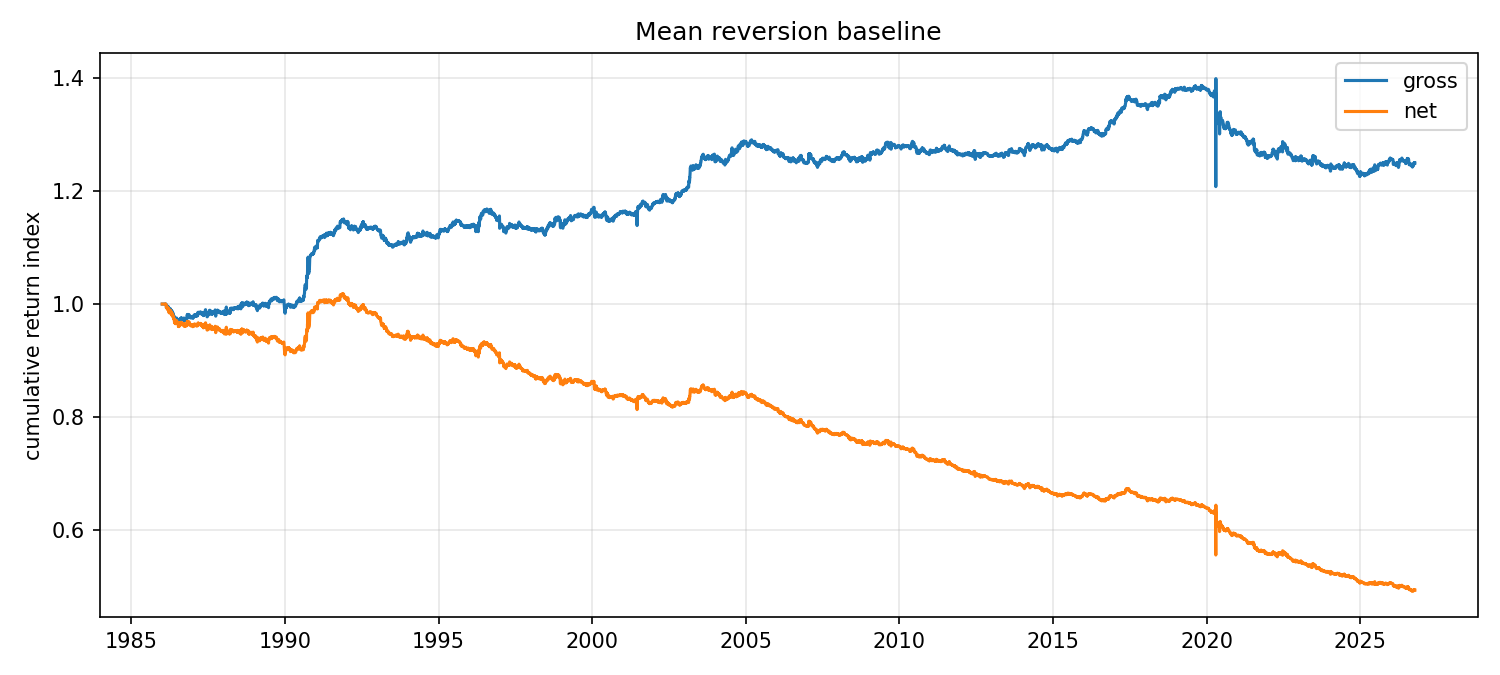

In [13]:
path = metrics.plot_result(
    full, "output/mean_reversion_cumulative.png", title="Mean reversion baseline"
)
display(Image(filename=str(path)))


## 10. Read this baseline

这是一个**负结果**（net）：

- Full sample：gross ann. +0.53%，net −1.67%，net Sharpe −0.03；
  turnover 约 22.6×/年，成本拖累约 2.2%/年。
- Train 1986–2015：gross +0.87%，net −1.32%，net Sharpe −0.045。
- Test 2016–2026：gross −0.39%，net −2.64%，net Sharpe −0.025。
- Energy 1992–2013 sanity check：gross −1.05%，net −3.12%，net Sharpe −0.04；
  我们的 1:1 版本没有复现论文的能源正结果（论文用的是 Kalman hedge ratio）。

Conditional mean：

- Full sample：`target_positive` +0.000017（t 0.11），`target_negative`
  +0.000101（t 1.28）；都不显著。
- Train：`target_negative` 的 raw mean 为 −0.000203（t −2.12），
  即 short-spread 在 train 里有方向；但 test 变成 −0.000148（t −1.05），
  不显著且方向不稳。
- 所以：**没有证据表明 C 在这个最粗的 1:1 weekly baseline 里有稳健、
  可交易的 edge。**

Sector gross Sharpe 的差异（Grains / Industrials / Softs 为正，Energy 为负）
只能作为描述，不能当作结论；成本没有分摊到 sector。

**这不是最终结论。** 这个 baseline 只检验了：
C2 additive index、dollar z、L=20、weekly、1:1、5 bps、settlement fill。
下一步应该是 carry-neutral 和 daily / hedge-ratio，而不是在 test 上调参。


Hedge-ratio variant（section 11）也没有改善 gross；见下一节。


## 11. Rolling OLS hedge-ratio robustness (gross, 0 bps)

用 60 天 rolling OLS levels 估 `h_t = Cov(near, far) / Var(far)`，构造
`p_t = near_index − h_t·far_index`；同一个 L=20 / ±2/0 / weekly 状态机。
交易严格按 h 调仓：near units = target，far units = −target·h。
这一节只看 **0 bps gross**，先隔离 hedge ratio 的 effect；1:1 也在 0 bps 下重跑。


In [14]:
hedge_panel = continuous.rolling_ols_hedge_ratio(leg, window=60)
h_valid = hedge_panel.loc[hedge_panel["hedge_ratio_valid"]]
print("valid h share:", round(float(hedge_panel["hedge_ratio_valid"].mean()), 3))
print(h_valid["hedge_ratio"].quantile([0.01, 0.05, 0.50, 0.95, 0.99]).round(3).to_string())
h_by_root = h_valid.groupby("root")["hedge_ratio"].agg(
    median="median",
    p05=lambda s: s.quantile(0.05),
    p95=lambda s: s.quantile(0.95),
    n="size",
)
display(h_by_root.sort_values("median").iloc[[0, 1, 2, -3, -2, -1]])


valid h share: 0.993
0.01    0.555
0.05    0.796
0.50    1.008
0.95    1.312
0.99    1.612


,median,p05,p95,n
root,,,,
S,0.990494,0.813112,1.134188,10212
FC,0.992319,0.727449,1.237684,9770
LH,0.992719,0.500375,1.520920,10090
CO,1.047581,0.864910,1.264279,9724
SB,1.047691,0.796734,1.408192,10167
LB,1.084700,0.777915,1.463662,9165


In [15]:
hedge_sig = signals.mean_reversion_signal(
    hedge_panel[["date", "root", "commodity", "sector", "spread_index"]],
    params,
    trading_days=trading_days,
    pair_grid=bt["pairs"][["date", "root"]],
)
hedge_sig = hedge_sig.merge(
    hedge_panel[["date", "root", "hedge_ratio", "hedge_ratio_valid"]],
    on=["date", "root"], how="left", validate="many_to_one",
)
valid_h = hedge_sig["hedge_ratio_valid"].fillna(False).astype(bool)
hedge_sig.loc[~valid_h, "target"] = 0.0
hedge_targets = backtest.build_target_legs(hedge_sig, bt["spread"])
print("hedge signal rows:", len(hedge_sig))
print(hedge_sig["target"].value_counts().to_string())


hedge signal rows: 252168
target
 0.0    122965
-1.0     65388
 1.0     63815


In [16]:
zero_cost = backtest.BacktestConfig(cost_bps_per_leg=0.0)
test_zero = backtest.BacktestConfig(cost_bps_per_leg=0.0, start_date="2016-01-01")
full_1_0 = backtest.run_backtest(bt["spread"], bt["contract"], targets, zero_cost, mark_state=mark)
test_1_0 = backtest.run_backtest(bt["spread"], bt["contract"], targets, test_zero, mark_state=mark)
hedge_full_0 = backtest.run_backtest(bt["spread"], bt["contract"], hedge_targets, zero_cost, mark_state=mark)
hedge_test_0 = backtest.run_backtest(bt["spread"], bt["contract"], hedge_targets, test_zero, mark_state=mark)

hedge_summary = pd.concat(
    [
        metrics.summarize(full_1_0).assign(variant="1:1", period="full"),
        metrics.summarize(full_1_0, end="2015-12-31").assign(variant="1:1", period="train"),
        metrics.summarize(test_1_0).assign(variant="1:1", period="test"),
        metrics.summarize(hedge_full_0).assign(variant="hedge", period="full"),
        metrics.summarize(hedge_full_0, end="2015-12-31").assign(variant="hedge", period="train"),
        metrics.summarize(hedge_test_0).assign(variant="hedge", period="test"),
    ],
    ignore_index=True,
)
hedge_summary.to_csv("output/mean_reversion_hedge_summary.csv", index=False)
display(hedge_summary[["variant", "period", "ann_return_gross", "ann_vol_gross", "sharpe_gross", "max_drawdown_net", "turnover", "n_trades"]])


,variant,period,ann_return_gross,ann_vol_gross,sharpe_gross,max_drawdown_net,turnover,n_trades
0,1:1,full,0.005349,0.035770,0.010499,-0.128923,22.645920,28645
1,1:1,train,0.008683,0.018272,0.030382,-0.043290,22.692431,20163
2,1:1,test,-0.003906,0.062449,-0.002031,-0.128923,22.567795,8476
3,hedge,full,0.001972,0.026177,0.005578,-0.120966,20.405841,56289
4,hedge,train,0.002899,0.015433,0.012301,-0.086741,20.293702,40476
5,hedge,test,-0.000552,0.043868,0.000615,-0.120966,20.560188,15798


In [17]:
hedge_cond = pd.concat(
    [
        metrics.conditional_mean(full_1_0, sig, bootstrap=500).assign(variant="1:1", period="full"),
        metrics.conditional_mean(metrics._slice(full_1_0, None, "2015-12-31"), sig, bootstrap=500).assign(variant="1:1", period="train"),
        metrics.conditional_mean(test_1_0, sig, bootstrap=500).assign(variant="1:1", period="test"),
        metrics.conditional_mean(hedge_full_0, hedge_sig, bootstrap=500).assign(variant="hedge", period="full"),
        metrics.conditional_mean(metrics._slice(hedge_full_0, None, "2015-12-31"), hedge_sig, bootstrap=500).assign(variant="hedge", period="train"),
        metrics.conditional_mean(hedge_test_0, hedge_sig, bootstrap=500).assign(variant="hedge", period="test"),
    ],
    ignore_index=True,
)
hedge_cond.to_csv("output/mean_reversion_hedge_conditional_mean.csv", index=False)
display(hedge_cond[["variant", "period", "group", "n_obs", "mean", "t_stat", "raw_mean", "raw_t_stat"]])


,variant,period,group,n_obs,mean,t_stat,raw_mean,raw_t_stat
0,1:1,full,target_positive,8452,0.000017,0.110217,0.000017,0.110217
1,1:1,full,target_negative,8980,0.000101,1.283063,-0.000101,-1.283063
2,1:1,train,target_positive,6012,0.000112,1.724774,0.000112,1.724774
3,1:1,train,target_negative,6365,0.000203,2.122473,-0.000203,-2.122473
4,1:1,test,target_positive,2439,-0.000217,-0.400102,-0.000217,-0.400102
5,1:1,test,target_negative,2612,-0.000148,-1.046101,0.000148,1.046101
6,hedge,full,target_positive,13017,0.000057,0.468716,0.000057,0.468716
7,hedge,full,target_negative,13362,-0.000020,-0.324282,0.000020,0.324282
8,hedge,train,target_positive,9334,0.000073,1.161023,0.000073,1.161023
9,hedge,train,target_negative,9803,-0.000005,-0.069623,0.000005,0.069623


In [18]:
e_sig_1_0 = sig.loc[sig["root"].isin(energy_roots)].copy()
e_sig_h = hedge_sig.loc[hedge_sig["root"].isin(energy_roots)].copy()
e_targets_1_0 = backtest.build_target_legs(e_sig_1_0, e_spread)
e_targets_h = backtest.build_target_legs(e_sig_h, e_spread)
energy_cfg = backtest.BacktestConfig(
    cost_bps_per_leg=0.0, start_date="1992-01-01", end_date="2013-12-31"
)
energy_1_0 = backtest.run_backtest(e_spread, e_contract, e_targets_1_0, energy_cfg, mark_state=e_mark)
energy_h_0 = backtest.run_backtest(e_spread, e_contract, e_targets_h, energy_cfg, mark_state=e_mark)
energy_compare = pd.concat(
    [
        metrics.summarize(energy_1_0).assign(variant="1:1"),
        metrics.summarize(energy_h_0).assign(variant="hedge"),
    ],
    ignore_index=True,
)
energy_compare.to_csv("output/mean_reversion_hedge_energy.csv", index=False)
display(energy_compare[["variant", "ann_return_gross", "ann_vol_gross", "sharpe_gross", "turnover", "n_trades"]])


,variant,ann_return_gross,ann_vol_gross,sharpe_gross,turnover,n_trades
0,1:1,-0.010525,0.046832,-0.012756,25.060054,3291
1,hedge,-0.000958,0.046701,0.000183,24.063361,6562


**读这一节：** h 的中位数约 1.008，5–95% 在 0.80–1.31；99.3% 有效。
rolling OLS 的 hedge portfolio 和 1:1 spread 非常接近。

0 bps gross：

- 1:1 full +0.535% / Sharpe 0.010；hedge full +0.197% / Sharpe 0.006；
- train：1:1 +0.868% / 0.030；hedge +0.290% / 0.012；
- test：1:1 −0.391% / −0.002；hedge −0.055% / 0.001。

Full/train/test 里 hedge 版本 vol 更低，但 return 也更低，Sharpe 没有改善；
strict h 调仓还让 trade 数从约 28.6k 增加到 56.3k。Conditional mean 也没有
稳健改善：hedge 的 `target_negative` raw mean 从 1:1 的 −0.000101 变成
+0.000020，但 full-sample t 只有 0.32。

Energy 1992–2013（0 bps）是一个小例外：1:1 gross −1.05% / Sharpe −0.013；
hedge −0.10% / Sharpe 0.0002。Hedge 在能源上“没那么差”，但仍然没有正的
edge。

**结论：rolling OLS hedge ratio 在 full/train/test 没有改善 C 的 gross
结果；energy 只是从负接近零，仍不足以继续跑 5 bps。**


## 12. 下一步

- C 的 1:1 baseline 和 rolling-OLS hedge-ratio variant 都是负结果；
  不再对 C 做成本/参数调优。
- 如果还要继续 C：returns-based h、20/120 天窗口、h cap、Kalman 复现；
  这些是独立 robustness，不改变主结论。
- 转向 B/D/H，或 A 的 robustness（A 在独立分支）。
- 报告里保留负结果；不要用 2016–2026 test 调参。
